# Task 2: California Housing Price Prediction using Ridge & Lasso
In this notebook, I am working on predicting median house values using the California Housing dataset. 
I will handle feature scaling, impute missing values if any, perform feature engineering, and compare Linear Regression (OLS), Ridge, and Lasso models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Step 1: Loading Data and Exploratory Data Analysis
Loading dataset directly from Scikit-Learn and building a pandas DataFrame for EDA.

Data shape: (20640, 9)


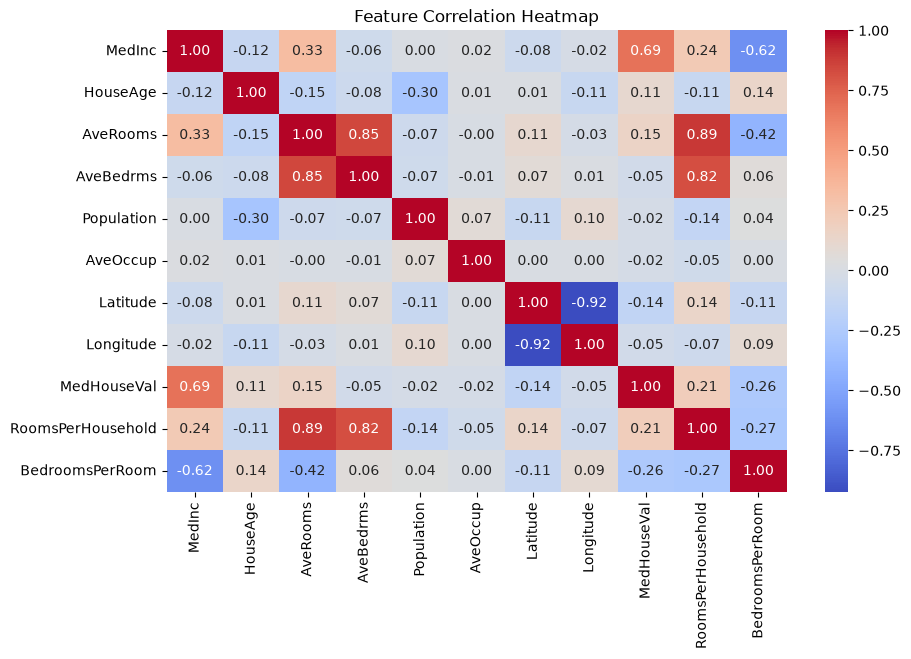

In [2]:
# Load California Housing Dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Data shape:", df.shape)
df.head()

# Creating simple interaction features (common practice in housing datasets)
df['RoomsPerHousehold'] = df['AveRooms'] / df['AveOccup']
df['BedroomsPerRoom'] = df['AveBedrms'] / df['AveRooms']

# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

## Step 2: Data Preprocessing
Handling missing values using SimpleImputer, splitting data (80/20), and scaling features using StandardScaler.

In [3]:
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Split train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Imputing potential null values (if any)
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Training features shape:", X_train_scaled.shape)
print("Testing features shape:", X_test_scaled.shape)

Training features shape: (16512, 10)
Testing features shape: (4128, 10)


## Step 3: Model Training & Hyperparameter Tuning
Training Linear Regression, Ridge, and Lasso using GridSearchCV to find best alpha values.

In [4]:
# 1. Baseline OLS Linear Regression
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)
y_pred_ols = ols.predict(X_test_scaled)

# 2. Ridge Regression with GridSearchCV
ridge_params = {'alpha': [0.1, 1.0, 10.0, 50.0, 100.0]}
ridge_grid = GridSearchCV(Ridge(), ridge_params, cv=5, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)
best_ridge = ridge_grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test_scaled)

# 3. Lasso Regression with GridSearchCV
lasso_params = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}
lasso_grid = GridSearchCV(Lasso(max_iter=5000), lasso_params, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)
best_lasso = lasso_grid.best_estimator_
y_pred_lasso = best_lasso.predict(X_test_scaled)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Lasso Alpha:", lasso_grid.best_params_)

Best Ridge Alpha: {'alpha': 50.0}
Best Lasso Alpha: {'alpha': 0.001}


## Step 4: Model Comparison & Residual Analysis
Comparing RMSE, MAE, and R2 scores across models and plotting actual vs predicted values.

--- MODEL EVALUATION SUMMARY ---


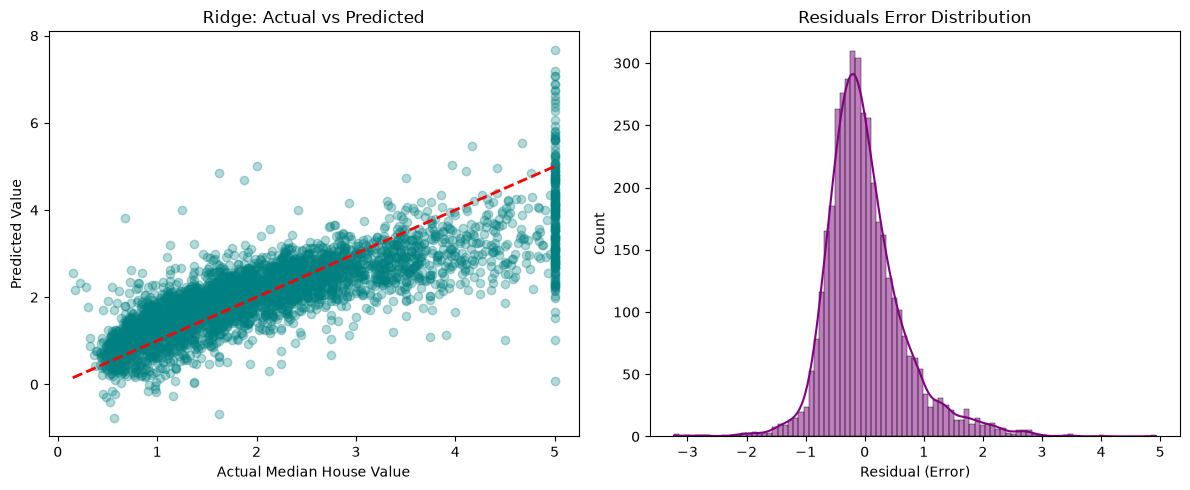

In [7]:
def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': name, 'RMSE': round(rmse, 4), 'MAE': round(mae, 4), 'R2 Score': round(r2, 4)}

results = [
    evaluate_model("OLS Linear Regression", y_test, y_pred_ols),
    evaluate_model("Ridge Regression", y_test, y_pred_ridge),
    evaluate_model("Lasso Regression", y_test, y_pred_lasso)
]

results_df = pd.DataFrame(results)
print("--- MODEL EVALUATION SUMMARY ---")


# Plotting Predicted vs Actual Values for Ridge Model
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_ridge, alpha=0.3, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Value")
plt.title("Ridge: Actual vs Predicted")

# Residual Distribution Plot
residuals = y_test - y_pred_ridge
plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='purple')
plt.title("Residuals Error Distribution")
plt.xlabel("Residual (Error)")

plt.tight_layout()
plt.show()